# Advanced ML: Random Forest and XGBoost
Tune both tree models with `TimeSeriesSplit` on the training period, select the winner using validation RMSE, then refit the winner on train + validation and evaluate the test period once.

In [7]:
from pathlib import Path
import json
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import clone

from ml.models.evaluation import (
    chronological_split,
    evaluate_regression as evaluate,
    safe_mape,
    summarize_time_series_folds,
)
from ml.models.ml_models import DEFAULT_RANDOM_STATE, tune_regressor

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 100)
RANDOM_STATE = DEFAULT_RANDOM_STATE

In [8]:
# Load dataset
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent

DECISION_PATH = PROJECT_ROOT / "artifacts" / "evaluation" / "final_model_decision.json"
FEATURE_PATH = PROJECT_ROOT / 'data' / 'features' / 'sales_time_features.csv'
FEATURE_METADATA_PATH = PROJECT_ROOT / 'data' / 'features' / 'sales_time_features_metadata.json'
BASELINE_METRICS_PATH = PROJECT_ROOT / 'artifacts' / 'reports' / 'baseline_model_metrics.csv'
MODEL_DIR = PROJECT_ROOT / 'artifacts' / 'models'
REPORT_DIR = PROJECT_ROOT / 'artifacts' / 'reports'
MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(FEATURE_PATH, parse_dates=['date']).sort_values('date').reset_index(drop=True)
feature_metadata = json.loads(FEATURE_METADATA_PATH.read_text(encoding='utf-8'))
decision = json.loads(DECISION_PATH.read_text(encoding="utf-8"))
TARGET = feature_metadata['target_column']
FEATURES = feature_metadata['feature_columns']

assert df['date'].is_monotonic_increasing and df['date'].is_unique
assert set(FEATURES).issubset(df.columns) and TARGET in df.columns
assert np.isfinite(df[FEATURES + [TARGET]].to_numpy(dtype=float)).all()
print(df.shape, df['date'].min(), df['date'].max(), len(FEATURES))
print("Selected model:",decision["selected_model"])

(649, 45) 2010-03-01 00:00:00 2011-12-09 00:00:00 43
Selected model: Prophet


In [9]:
# Reuse the shared chronological 70/15/15 split; the test partition stays out of tuning.
split = chronological_split(
    df,
    date_column='date',
    train_fraction=0.70,
    validation_fraction=0.15,
)
train_df = split.train
validation_df = split.validation
test_df = split.test

assert train_df['date'].max() < validation_df['date'].min()
assert validation_df['date'].max() < test_df['date'].min()

X_train, y_train = train_df[FEATURES], train_df[TARGET]
X_validation, y_validation = validation_df[FEATURES], validation_df[TARGET]
X_test, y_test = test_df[FEATURES], test_df[TARGET]
split.summary(date_column='date')

,split,rows,start,end
0,train,454,2010-03-01,2011-05-28
1,validation,97,2011-05-29,2011-09-02
2,test,98,2011-09-03,2011-12-09


In [10]:
# Reuse the shared fold summary to inspect the same expanding CV splits used by tuning.
fold_summary = summarize_time_series_folds(
    train_df,
    date_column='date',
    n_splits=5,
)
fold_summary

,fold,train_rows,train_start,train_end,cv_rows,cv_start,cv_end
0,1,79,2010-03-01,2010-05-18,75,2010-05-19,2010-08-01
1,2,154,2010-03-01,2010-08-01,75,2010-08-02,2010-10-15
2,3,229,2010-03-01,2010-10-15,75,2010-10-16,2010-12-29
3,4,304,2010-03-01,2010-12-29,75,2010-12-30,2011-03-14
4,5,379,2010-03-01,2011-03-14,75,2011-03-15,2011-05-28


In [11]:
# `evaluate` and `safe_mape` are imported from ml.models.evaluation.
# Keep these names for compatibility with the downstream notebook cells.

In [12]:
# Tune Random Forest on training data only; the package uses chronological TimeSeriesSplit.
start = time.perf_counter()
rf_search = tune_regressor(
    'random forest',
    X_train,
    y_train,
    n_iter=25,
    n_splits=5,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1,
)
rf_seconds = time.perf_counter() - start
print('Best CV RMSE:', -rf_search.best_score_)
print('Best parameters:', rf_search.best_params_)
print('Seconds:', round(rf_seconds, 1))

Fitting 5 folds for each of 25 candidates, totalling 125 fits
Best CV RMSE: 14078.940504743732
Best parameters: {'model__max_depth': 10, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 3, 'model__min_samples_split': 8, 'model__n_estimators': 220}
Seconds: 17.8


In [13]:
# Tune XGBoost on training data only with the shared chronological tuning helper.
start = time.perf_counter()
xgb_search = tune_regressor(
    'xgboost',
    X_train,
    y_train,
    n_iter=30,
    n_splits=5,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1,
)
xgb_seconds = time.perf_counter() - start
print('Best CV RMSE:', -xgb_search.best_score_)
print('Best parameters:', xgb_search.best_params_)
print('Seconds:', round(xgb_seconds, 1))

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best CV RMSE: 14924.964015210266
Best parameters: {'model__colsample_bytree': np.float64(0.8622501708808565), 'model__learning_rate': np.float64(0.021655469290993337), 'model__max_depth': 7, 'model__min_child_weight': 9, 'model__n_estimators': 298, 'model__reg_alpha': np.float64(0.9736638367553173), 'model__reg_lambda': np.float64(1.2098024368436642), 'model__subsample': np.float64(0.7568773511205378)}
Seconds: 19.8


In [14]:
#  Select the advanced model using validation only
rf_validation_pred = rf_search.best_estimator_.predict(X_validation)
xgb_validation_pred = xgb_search.best_estimator_.predict(X_validation)
validation_results = pd.DataFrame([
    evaluate('Random Forest', 'validation', y_validation, rf_validation_pred),
    evaluate('XGBoost', 'validation', y_validation, xgb_validation_pred),
]).sort_values('RMSE').reset_index(drop=True)
validation_results

,model,split,MAE,RMSE,MAPE_pct,R2
0,Random Forest,validation,7847.410410,10793.127518,40.877276,0.510540
1,XGBoost,validation,7776.940936,10841.430864,40.286231,0.506149


Selected using validation RMSE: Random Forest


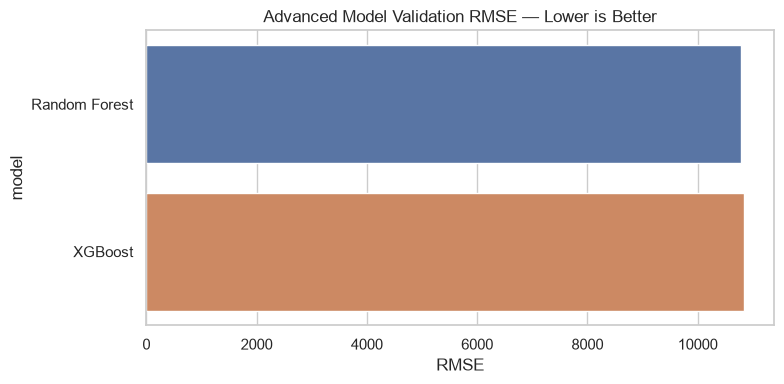

In [15]:
best_name = validation_results.iloc[0]['model']
best_pipeline = rf_search.best_estimator_ if best_name == 'Random Forest' else xgb_search.best_estimator_
print('Selected using validation RMSE:', best_name)

plt.figure(figsize=(8, 4))
sns.barplot(data=validation_results, x='RMSE', y='model', hue='model', legend=False)
plt.title('Advanced Model Validation RMSE — Lower is Better')
plt.tight_layout(); plt.show()

In [16]:
# Refit the selected model and evaluate test once
# After model selection, combine train and validation. Do not use test rows during fitting.
development_df = pd.concat([train_df, validation_df], ignore_index=True)
X_development, y_development = development_df[FEATURES], development_df[TARGET]
final_model = clone(best_pipeline)
final_model.fit(X_development, y_development)
test_prediction = final_model.predict(X_test)
final_test_result = pd.DataFrame([evaluate(best_name, 'test', y_test, test_prediction)])
final_test_result

,model,split,MAE,RMSE,MAPE_pct,R2
0,Random Forest,test,9439.614379,14086.096713,26.344286,0.652033


In [17]:
# Compare with baselines
if BASELINE_METRICS_PATH.exists():
    baseline_metrics = pd.read_csv(BASELINE_METRICS_PATH)
    test_comparison = pd.concat([
        baseline_metrics.query("split == 'test'"), final_test_result
    ], ignore_index=True).sort_values('RMSE').reset_index(drop=True)
    display(test_comparison)
else:
    test_comparison = final_test_result.copy()
    print('Baseline metrics not found; run Phase 7 first.')

,model,split,MAE,RMSE,MAPE_pct,R2
0,Random Forest,test,9439.614379,14086.096713,26.344286,0.652033
1,Linear Regression,test,17819.680883,21247.470421,47.060674,0.208282
2,Moving average 7,test,17960.917589,23447.974269,36.138788,0.035801
3,Naive lag-1,test,22677.058980,28886.711927,46.933541,-0.463364


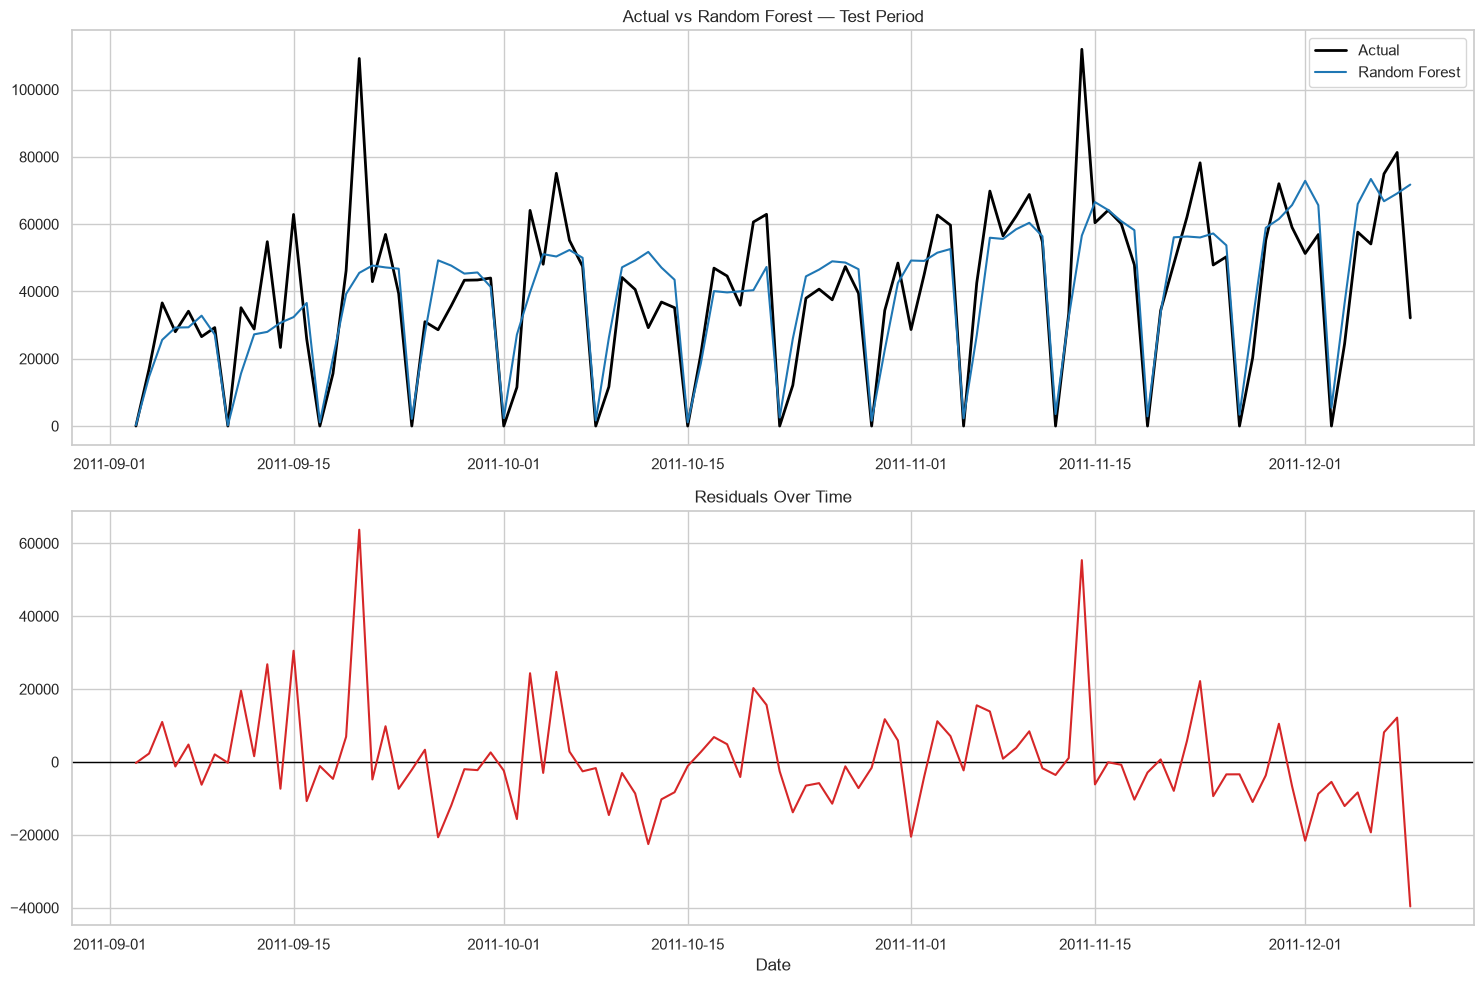

In [18]:
# Actual vs prediction and residual diagnostics
predictions = test_df[['date', TARGET]].copy()
predictions['prediction'] = test_prediction
predictions['residual'] = predictions[TARGET] - predictions['prediction']

fig, axes = plt.subplots(2, 1, figsize=(15, 10))
axes[0].plot(predictions['date'], predictions[TARGET], label='Actual', color='black', linewidth=2)
axes[0].plot(predictions['date'], predictions['prediction'], label=best_name, color='tab:blue')
axes[0].set_title(f'Actual vs {best_name} — Test Period'); axes[0].legend()
axes[1].axhline(0, color='black', linewidth=1)
axes[1].plot(predictions['date'], predictions['residual'], color='tab:red')
axes[1].set_title('Residuals Over Time'); axes[1].set_xlabel('Date')
plt.tight_layout(); plt.show()

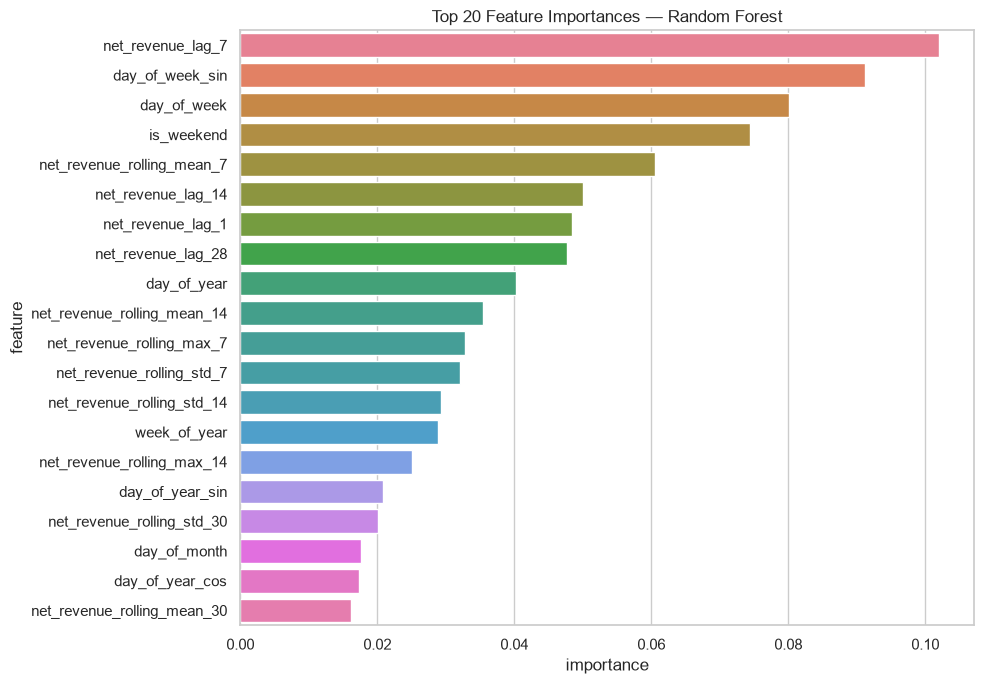

,feature,importance
0,net_revenue_lag_7,0.102002
1,day_of_week_sin,0.091234
2,day_of_week,0.080151
3,is_weekend,0.074438
4,net_revenue_rolling_mean_7,0.060526
5,net_revenue_lag_14,0.050021
6,net_revenue_lag_1,0.048437
7,net_revenue_lag_28,0.047660
8,day_of_year,0.040256
9,net_revenue_rolling_mean_14,0.035458


In [19]:
# Feature importance
tree_model = final_model.named_steps['model']
feature_importance = pd.DataFrame({
    'feature': FEATURES,
    'importance': tree_model.feature_importances_,
}).sort_values('importance', ascending=False).reset_index(drop=True)

plt.figure(figsize=(10, 7))
sns.barplot(data=feature_importance.head(20), x='importance', y='feature', hue='feature', legend=False)
plt.title(f'Top 20 Feature Importances — {best_name}')
plt.tight_layout(); plt.show()
feature_importance.head(20)

In [20]:
# Save reproducible artifacts
model_slug = best_name.lower().replace(' ', '_')
MODEL_PATH = MODEL_DIR / f'{model_slug}_final.joblib'
joblib.dump(final_model, MODEL_PATH)
validation_results.to_csv(REPORT_DIR / 'advanced_validation_metrics.csv', index=False)
final_test_result.to_csv(REPORT_DIR / 'advanced_test_metrics.csv', index=False)
test_comparison.to_csv(REPORT_DIR / 'all_model_test_comparison.csv', index=False)
predictions.to_csv(REPORT_DIR / 'advanced_test_predictions.csv', index=False)
feature_importance.to_csv(REPORT_DIR / 'advanced_feature_importance.csv', index=False)
pd.DataFrame(rf_search.cv_results_).to_csv(REPORT_DIR / 'random_forest_cv_results.csv', index=False)
pd.DataFrame(xgb_search.cv_results_).to_csv(REPORT_DIR / 'xgboost_cv_results.csv', index=False)

advanced_metadata = {
    'selected_model': best_name,
    'selection_metric': 'validation_RMSE',
    'target': TARGET,
    'features': FEATURES,
    'train_end': str(train_df.date.max().date()),
    'validation_end': str(validation_df.date.max().date()),
    'test_end': str(test_df.date.max().date()),
    'random_state': RANDOM_STATE,
    'best_parameters': best_pipeline.get_params(),
}
# Keep metadata JSON serializable.
advanced_metadata['best_parameters'] = {
    key: value for key, value in advanced_metadata['best_parameters'].items()
    if key.startswith('model__') and isinstance(value, (str, int, float, bool, type(None)))
}
(REPORT_DIR / 'advanced_model_metadata.json').write_text(
    json.dumps(advanced_metadata, indent=2), encoding='utf-8'
)
print('Saved:', MODEL_PATH)
print('completed successfully.')

Saved: D:\Research_Project\sales-forecasting-platform\artifacts\models\random_forest_final.joblib
completed successfully.


In [21]:
# create production XGBoost
X_full = df[FEATURES]
y_full = df[TARGET]
assert len(X_full) == len(y_full)

assert not X_full.isna().any().any()
assert not y_full.isna().any()

assert np.isfinite(
    X_full.to_numpy(
        dtype=float
    )
).all()

assert np.isfinite(
    y_full.to_numpy(
        dtype=float
    )
).all()

print(
    "Full training shape:",
    X_full.shape,
)


Full training shape: (649, 43)


In [22]:
# Clone best estimator
xgboost_final = clone(
    xgb_search.best_estimator_
)
xgboost_final.fit(
    X_full,
    y_full,
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](43,)","['day_of_week','day_of_month','day_of_year',..., 'net_revenue_expanding_std','net_revenue_expanding_min', 'net_revenue_expanding_max']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,43
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericalda

In [23]:
# Save XGBOOST MODEL
XGBOOST_MODEL_PATH = (
    MODEL_DIR
    / "xgboost_final.joblib"
)

joblib.dump(
    xgboost_final,
    XGBOOST_MODEL_PATH,
)

print(
    "Saved:",
    XGBOOST_MODEL_PATH,
)

Saved: D:\Research_Project\sales-forecasting-platform\artifacts\models\xgboost_final.joblib


In [24]:
#Check  XGBOOST model
assert (
    XGBOOST_MODEL_PATH.exists()
)

print(
    "File exists:",
    XGBOOST_MODEL_PATH.exists(),
)

print(
    "File size:",
    round(
        XGBOOST_MODEL_PATH.stat().st_size
        / 1024
        / 1024,
        2,
    ),
    "MB",
)

File exists: True
File size: 0.65 MB


In [25]:
# Reload check
loaded_xgboost = joblib.load(
    XGBOOST_MODEL_PATH
)

print(
    type(loaded_xgboost)
)

print(
    loaded_xgboost.named_steps
)

print(
    type(
        loaded_xgboost
        .named_steps["model"]
    )
)

<class 'sklearn.pipeline.Pipeline'>
{'imputer': SimpleImputer(strategy='median'), 'model': XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=np.float64(0.8622501708808565), device=None,
             early_stopping_rounds=None, enable_categorical=True,
             eval_metric='rmse', feature_types=None, feature_weights=None,
             gamma=None, grow_policy=None, importance_type=None,
             interaction_constraints=None,
             learning_rate=np.float64(0.021655469290993337), max_bin=None,
             max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=7, max_leaves=None,
             min_child_weight=9, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=298, n_jobs=1,
             num_parallel_tree=None, ...)}
<class 'xgboost.sklearn.XGBRegressor'>


In [26]:
# Smoke test prediction
sample_X = (
    X_full
    .tail(5)
    .copy()
)

sample_predictions = (
    loaded_xgboost.predict(
        sample_X
    )
)

print(
    sample_predictions
)

[64041.793 59537.14  72008.03  74800.81  43562.797]


In [27]:
# Test
assert len(
    sample_predictions
) == 5

assert np.isfinite(
    sample_predictions
).all()

print(
    "XGBoost artifact "
    "validation passed."
)

XGBoost artifact validation passed.


In [28]:
# Save metadata XGBoost
XGBOOST_METADATA_PATH = (
    MODEL_DIR
    / "xgboost_final_metadata.json"
)

xgboost_metadata = {
    "model": "XGBoost",

    "artifact": (
        "xgboost_final.joblib"
    ),

    "target": TARGET,

    "feature_count": len(
        FEATURES
    ),

    "feature_columns": FEATURES,

    "training_rows": len(
        X_full
    ),

    "training_start": str(
        df["date"]
        .min()
        .date()
    ),

    "training_end": str(
        df["date"]
        .max()
        .date()
    ),

    "best_parameters": {
        key: (
            value.item()
            if hasattr(
                value,
                "item",
            )
            else value
        )
        for key, value
        in xgb_search
        .best_params_
        .items()
    },
}

XGBOOST_METADATA_PATH.write_text(
    json.dumps(
        xgboost_metadata,
        indent=2,
    ),
    encoding="utf-8",
)

print(
    "Saved:",
    XGBOOST_METADATA_PATH,
)

Saved: D:\Research_Project\sales-forecasting-platform\artifacts\models\xgboost_final_metadata.json


## Completion criteria

- Hyperparameters were tuned with past-to-future folds only.
- Model selection used validation RMSE, never test RMSE.
- Test was evaluated once after refitting the selected model.
- The winning pipeline, metrics, predictions, CV results, and feature importance were saved.